# Inteligencia Artificial
## 2º Examen Práctico de Evluación Alternativa 25/26
## Grupo 1

In [ ]:
# Apellidos:
# Nombre:

### Parte 1

Vamos a implementar la propagación hacia delante en redes neuronales multi-capa. Las redes que manejaremos estarán compuestas por una capa de entrada, un número variable de capas ocultas (intermedias) y una capa de salida. El número de neuronas en cada capa también será variable. Tanto el número de capas como el número de unidades de cada capa estarán implícitos en la estructura de datos en la que proporcionamos los pesos. 

Como función de activación en las capas intermedias utilizaremos la tangente hiperbólica y en la capa de salida utilizaremos la función _softmax_ para utilizar la red como clasificador muti-clase. Por último, evaluaremos el rendimiento de una red entrenada utilizando una función de evaluación. Para medir el error, utilizaremos una nueva métrica llamada entropia cruzada.

En la capa de salida utilizaremos la función _softmax_ que recibe una lista de valores y devuelve la lista de esos valores normalizados como una distribución de probabilidad.

In [ ]:
import math

def softmax(values):
    values = list(map(lambda x: math.exp(x), values))
    return list(map(lambda x: x/sum(values),values))

In [ ]:
##### Prueba:
softmax([-1,2,3.2,-4.5])

### Ejercicio 1 [0.75 ptos]

En este ejercicio implementaremos una función auxiliar que calcule lo que llega a cada unidad de una capa (el $in_i$, según la notación de las diapositivas), en función de lo que sale de la capa inmediatamente anterior. De momento no consideraremos aún los pesos umbrales o _bias_.

Para ello consideraremos que la capa $r$ tiene $n$ neuronas y la capa $r+1$ tiene $m$ neuronas. Representaremos los pesos entre ambas capas como una lista $[l_1,\dots,l_n]$ donde cada $l_i$ es la lista de los pesos de las conexiones **que *salen* de la unidad $i$**. Es decir, cada $l_i$ es su vez es una lista de pesos $[w_{i1},\dots , w_{im}]$ con $w_{ij}$ el peso de la conexión entre la $i$-ésima neurona de la capa $r$ con la $j$-ésima neurona de la capa $r+1$. 

* Un ejemplo: si tenemos una capa $r$ con dos unidades y la siguiente capa $r+1$ tiene tres unidades, lo siguiente podría ser una estructura para los pesos:

`[[0.4, 0.27, 0.32],
  [0.6, -0.8, -0.63]]`
  
Aquí por ejemplo, 0.27 sería el peso de la conexión entre la primera unidad de la capa $r$ y la segunda unidad de la capa $r+1$. Y -0.63 sería el peso entre la segunda unidad de la capa $r$ y la tercera unidad de la capa $r+1$.   

* Otro ejemplo: pesos que conectan una capa de tres unidades con una capa con una única unidad:

`[[-0.18], [1.26], [-0.72]]`

donde por ejemplo -0.18 conectaría la primera unidad de la capa $r$ con la primera (y única) unidad de la capa $r+1$

* Un último ejemplo: una capa de 1 unidad conectada con una capa de 5 unidades.

`[[1,0.5,0.4,-0.9,0.75]]`

aquí por ejemplo -0.9 sería el peso que conecta la única unidad de la capa $r$ con la cuarta unidad de la capa $r+1$

Se pide implementar una  función `calcula_entradas(pesos,valores)` que tome como entrada una estructura de pesos entre las capas $r$ y $r+1$ (tal como se ha definido en el párrafo anterior) y una lista de $n$ valores, que son los valores emitidos por las $n$ neuronas de la capa $r$. La función devuelve una lista de $m$ nuevos valores (uno por cada neurona de la capa $r+1$) obtenidos tras hacer el sumatorio de los _valores_ multiplicados por los pesos correspondientes. (Nota: aún no estamos teniendo en cuenta los pesos umbrales).

In [ ]:
####Solución:


In [ ]:
# 2 unidades en la capa r, 3 unidades en la capa r+1
calcula_entradas([[0.4, 0.27, 0.32],[0.6, -0.8, -0.63]],[1,-0.6])
# Salida: [0.040000000000000036, 0.75, 0.698]

In [ ]:
# 3 unidades en la capa r, 1 unidad en la capa r+1
calcula_entradas([[-0.18], [1.26], [-0.72]],[2.91,5,10])
# Salida: [-1.4237999999999995]

In [ ]:
# 1 unidad en la capa r, 5 unidades en la capa r+1
calcula_entradas([[1,0.5,0.4,-0.9,0.75]],[0.25])
# Salida: [0.25, 0.125, 0.1, -0.225, 0.1875]

### Ejercicio 2 [0.5 pts]

En este ejercicio, vamos a definir otra función auxiliar para continuar con la implementación de la propagación hacia delante de la red neuronal multi-capa. Para ello defina un método `calcula_activaciones(entradas, bias)` que calcule las activaciones de las neuronas en una capa. El método recibe las entradas a cada neurona (calculadas con el método `calcula_entradas`) y la lista de pesos umbrales de cada neurona (bias) y devuelve, para cada neurona, la aplicación de la función de activación (`math.tanh`) sobre la suma de su entrada y su bias.

In [ ]:
#### Solución:


In [ ]:
calcula_activaciones([0.25,  0.1875],[0.2,0.5])
#Salida esperada: [0.4218990052500079, 0.5963735554792423]

In [ ]:
calcula_activaciones([0.5,  0.1],[0.05,0.5])
#Salida esperada: [0.5005202111902353, 0.5370495669980353]

In [ ]:
calcula_activaciones([0.2,  0.8],[0.2,0.01])
#Salida esperada: [0.3799489622552249, 0.6695902596187707]

### Ejercicio 3 [1 pto]

En este ejercicio, vamos a implementar la clase `FFNN` (de _feed forward neural network_) que hará uso de los métodos desarrollados en los ejercicios anteriores y que nos va a servir para realizar el cálculo de una red neuronal multicapa. 

El constructor de esta clase recibe los pesos entre neuronas de las sucesivas capas y además los pesos de la entrada ficticia de cada neurona (lo que conocemos como pesos umbral o _bias_). Con estos datos quedará determinada la estructura de la red, ya que sabremos cuántas capas hay, cuántas neuronas hay en cada capa y todos los pesos necesarios para hacer los cálculos). 

En concreto, el constructor de la clase recibe (para una red con $L$ capas):
* pesos: una lista $[c_1,\ldots,c_{L-1}]$ donde cada $c_r$ a su vez es una estructura con los pesos que conectan la capa $r$ con la capa $r+1$, como se ha descrito en el Ejercicio 1
* bias: una lista $[u_2,\ldots,u_L]$, donde cada $u_r$ es la lista de pesos umbrales de las unidades de la capa $r$. 

Veamos varios ejemplos.

**Ejemplo 1:**  Las siguientes estructuras:

   - pesos: `[[[0.5]],[[1]]]`
   - bias: `[[0.2],[0.3]]`
   
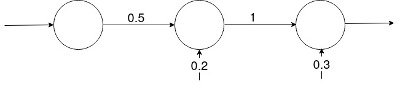

Representan una red neuronal con una neurona en la capa de entrada, una capa oculta compuesta por una neurona y una neurona en la capa de salida. El peso desde la neurona de la capa de entrada hasta la neurona de la capa oculta es 0.5, el peso desde la neurona en la capa oculta hasta la neurona en la capa de salida es 1. El bias de la neurona en la capa oculta es 0.2 y el de la neurona en el capa de salida es 0.3.

**Ejemplo 2:** En el siguiente ejemplo se representa una red con una neurona en la capa de entrada, una capa oculta con una neurona y dos neuronas en la capa de salida. El peso desde la neurona de la capa de entrada hasta la neurona en la capa oculta es 0.1 y los pesos desde la neurona en la capa oculta hasta las neuronas en la capa de salida son ambos 1. En este caso el bias asociado a la neurona en la capa oculta es 0.4 y los bias asociados a las neuronas en la capa de salida son 0.5 y 0.6 respectivamente.

   * pesos: `[[[0.1]],[[1,1]]]`
   * bias: `[[0.4],[0.5,0.6]]`
   
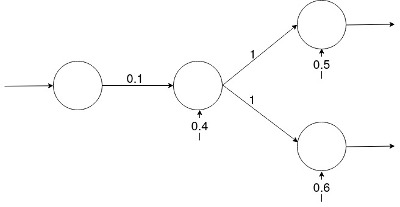

**Ejemplo 3:** A continuación se presenta las estructuras que describen una red neuronal con dos neuronas en la capa de entrada, dos neuronas en la capa oculta y tres neuronas en la capa de salida.

* pesos: `[[[0.1,0.05],[0.3,0.1]],[[0.1,0.6,0.7],[0.2,0.4,0.1]]]`
* bias: `[[0.4,0.4],[0.2,0.6,0.2]]`

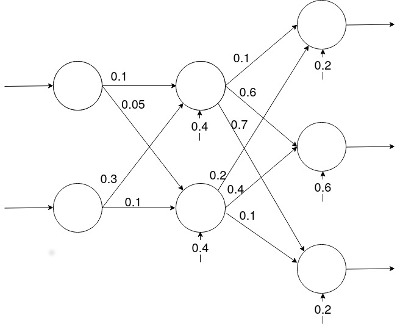

La clase `FFNN` debe implementar un método `calcula` que recibe como entrada una lista con los valores de entrada de la red y devuelve el resultado calculado por la red a partir de dicha entrada.

**Nota**: Usamos la tangente hiperbólica (`math.tanh`) como función de activación y _softmax_ en la última capa. 

In [ ]:
#### Solución:


In [ ]:
# Ejemplo 1
red = FFNN( [[[0.5]],[[1]]],[[0.2],[0.3]])
red.calcula([1])
# Salida esperada: [1.0]

In [ ]:
# Ejemplo 2
red = FFNN([[[0.1]],[[1,1]]],[[0.4],[0.5,0.6]])
red.calcula([1])
# Salida esperada: [0.4750208125210601, 0.52497918747894]

In [ ]:
# Ejemplo 3
pesos_ej = [[[0.1,0.05],[0.3,0.1]],[[0.1,0.6,0.7],[0.2,0.4,0.1]]]
bias_ej = [[0.4,0.4],[0.2,0.6,0.2]]
red = FFNN(pesos_ej,bias_ej)
red.calcula([1,1])
# Salida esperada: [0.2120914289728294, 0.4874266793602153, 0.30048189166695544]

### Parte 2

A continuación se presentan 150 ejemplos de datos sobre la planta iris y su clasificación en tres tipos distintos. Los ejemplos y la correspondiente clasificación están separados pero en el mismo orden:

In [ ]:
ejemplos_iris=[[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.2],
       [5. , 3.2, 1.2, 0.2],
       [5.5, 3.5, 1.3, 0.2],
       [4.9, 3.6, 1.4, 0.1],
       [4.4, 3. , 1.3, 0.2],
       [5.1, 3.4, 1.5, 0.2],
       [5. , 3.5, 1.3, 0.3],
       [4.5, 2.3, 1.3, 0.3],
       [4.4, 3.2, 1.3, 0.2],
       [5. , 3.5, 1.6, 0.6],
       [5.1, 3.8, 1.9, 0.4],
       [4.8, 3. , 1.4, 0.3],
       [5.1, 3.8, 1.6, 0.2],
       [4.6, 3.2, 1.4, 0.2],
       [5.3, 3.7, 1.5, 0.2],
       [5. , 3.3, 1.4, 0.2],
       [7. , 3.2, 4.7, 1.4],
       [6.4, 3.2, 4.5, 1.5],
       [6.9, 3.1, 4.9, 1.5],
       [5.5, 2.3, 4. , 1.3],
       [6.5, 2.8, 4.6, 1.5],
       [5.7, 2.8, 4.5, 1.3],
       [6.3, 3.3, 4.7, 1.6],
       [4.9, 2.4, 3.3, 1. ],
       [6.6, 2.9, 4.6, 1.3],
       [5.2, 2.7, 3.9, 1.4],
       [5. , 2. , 3.5, 1. ],
       [5.9, 3. , 4.2, 1.5],
       [6. , 2.2, 4. , 1. ],
       [6.1, 2.9, 4.7, 1.4],
       [5.6, 2.9, 3.6, 1.3],
       [6.7, 3.1, 4.4, 1.4],
       [5.6, 3. , 4.5, 1.5],
       [5.8, 2.7, 4.1, 1. ],
       [6.2, 2.2, 4.5, 1.5],
       [5.6, 2.5, 3.9, 1.1],
       [5.9, 3.2, 4.8, 1.8],
       [6.1, 2.8, 4. , 1.3],
       [6.3, 2.5, 4.9, 1.5],
       [6.1, 2.8, 4.7, 1.2],
       [6.4, 2.9, 4.3, 1.3],
       [6.6, 3. , 4.4, 1.4],
       [6.8, 2.8, 4.8, 1.4],
       [6.7, 3. , 5. , 1.7],
       [6. , 2.9, 4.5, 1.5],
       [5.7, 2.6, 3.5, 1. ],
       [5.5, 2.4, 3.8, 1.1],
       [5.5, 2.4, 3.7, 1. ],
       [5.8, 2.7, 3.9, 1.2],
       [6. , 2.7, 5.1, 1.6],
       [5.4, 3. , 4.5, 1.5],
       [6. , 3.4, 4.5, 1.6],
       [6.7, 3.1, 4.7, 1.5],
       [6.3, 2.3, 4.4, 1.3],
       [5.6, 3. , 4.1, 1.3],
       [5.5, 2.5, 4. , 1.3],
       [5.5, 2.6, 4.4, 1.2],
       [6.1, 3. , 4.6, 1.4],
       [5.8, 2.6, 4. , 1.2],
       [5. , 2.3, 3.3, 1. ],
       [5.6, 2.7, 4.2, 1.3],
       [5.7, 3. , 4.2, 1.2],
       [5.7, 2.9, 4.2, 1.3],
       [6.2, 2.9, 4.3, 1.3],
       [5.1, 2.5, 3. , 1.1],
       [5.7, 2.8, 4.1, 1.3],
       [6.3, 3.3, 6. , 2.5],
       [5.8, 2.7, 5.1, 1.9],
       [7.1, 3. , 5.9, 2.1],
       [6.3, 2.9, 5.6, 1.8],
       [6.5, 3. , 5.8, 2.2],
       [7.6, 3. , 6.6, 2.1],
       [4.9, 2.5, 4.5, 1.7],
       [7.3, 2.9, 6.3, 1.8],
       [6.7, 2.5, 5.8, 1.8],
       [7.2, 3.6, 6.1, 2.5],
       [6.5, 3.2, 5.1, 2. ],
       [6.4, 2.7, 5.3, 1.9],
       [6.8, 3. , 5.5, 2.1],
       [5.7, 2.5, 5. , 2. ],
       [5.8, 2.8, 5.1, 2.4],
       [6.4, 3.2, 5.3, 2.3],
       [6.5, 3. , 5.5, 1.8],
       [7.7, 3.8, 6.7, 2.2],
       [7.7, 2.6, 6.9, 2.3],
       [6. , 2.2, 5. , 1.5],
       [6.9, 3.2, 5.7, 2.3],
       [5.6, 2.8, 4.9, 2. ],
       [7.7, 2.8, 6.7, 2. ],
       [6.3, 2.7, 4.9, 1.8],
       [6.7, 3.3, 5.7, 2.1],
       [7.2, 3.2, 6. , 1.8],
       [6.2, 2.8, 4.8, 1.8],
       [6.1, 3. , 4.9, 1.8],
       [6.4, 2.8, 5.6, 2.1],
       [7.2, 3. , 5.8, 1.6],
       [7.4, 2.8, 6.1, 1.9],
       [7.9, 3.8, 6.4, 2. ],
       [6.4, 2.8, 5.6, 2.2],
       [6.3, 2.8, 5.1, 1.5],
       [6.1, 2.6, 5.6, 1.4],
       [7.7, 3. , 6.1, 2.3],
       [6.3, 3.4, 5.6, 2.4],
       [6.4, 3.1, 5.5, 1.8],
       [6. , 3. , 4.8, 1.8],
       [6.9, 3.1, 5.4, 2.1],
       [6.7, 3.1, 5.6, 2.4],
       [6.9, 3.1, 5.1, 2.3],
       [5.8, 2.7, 5.1, 1.9],
       [6.8, 3.2, 5.9, 2.3],
       [6.7, 3.3, 5.7, 2.5],
       [6.7, 3. , 5.2, 2.3],
       [6.3, 2.5, 5. , 1.9],
       [6.5, 3. , 5.2, 2. ],
       [6.2, 3.4, 5.4, 2.3],
       [5.9, 3. , 5.1, 1.8]]

In [ ]:
clases_iris = [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]

A continuación se ofrecen los pesos y bias obtenidos tras entrenar (con los 150 ejemplos presentados) una red `FFNN` con cuatro neuronas en la capa de entrada, una capa oculta con tres neuronas y tres neuronas en la capa de salida:

In [ ]:
pesos = [[[ 9.63378229e-01,  6.93107748e-01],
          [ 6.42743796e-01, -2.42014417e-04],
          [-1.43821777e+00, -1.25527381e+00],
          [-1.47684753e+00, -1.02146920e+00]],
        [[ 0.53056102,  1.35145844, -1.9763765],
         [1.87757178, -1.66613583, -0.39643955]]]

bias = [[1.48929693, 0.39655274],
        [ 0.1021882 , -0.5889176 ,  0.16863265]]

### Ejercicio 4 [0.5 pts]:

Este ejercicio tiene 3 apartados:

**Apartado 4.1:** Utilizando la clase `FFNN` y los pesos y bias presentados, calcula la probabilidad asociada a cada clase para el **primer ejemplo** de la lista `ejemplos_iris` (recuerda que la salida de la función softmax se intepreta como la probabilidad de pertenecer a cada clase):

In [ ]:
#Solución

# Salida: [0.9546842119606685, 0.03598008176186274, 0.00933570627746878]

**Apartado 4.2:** Define una función `evalua(red,ejemplo,clase)`que sea capaz de evaluar si la clase más probable calculada por una red neuronal FFNN para un ejemplo dado coincide con la clase pasada como parámetro:

In [ ]:
#Solución


In [ ]:
# Ejemplo 1:
evalua(red,ejemplos_iris[0],clases_iris[0])
# Salida: True 

In [ ]:
# Ejemplo 2:
evalua(red,ejemplos_iris[0],1)
# Salida: False

**Apartado 4.3:** A continuación, calcula la proporción de aciertos que obtiene la red sobre el conjunto Iris

In [ ]:
#Solución

# Salida: 0.9866666666666667

### Ejercicio 5 [0.75 pts]:
Vamos a implementar ahora la métrica de _entropía cruzada_ para evaluar la capacidad de una red neuronal a la hora de clasificar adecuadamente un conjunto de ejemplos en un problema de clasificación multiclase. La entropía cruzada (no confundir con la entropía usada en el algoritmo id3) es una medida del error cometido, que en muchas situaciones se emplea en lugar del error cuadrático que hemos visto en las diapositivas, sobre todo en clasificadores multiclase.   

Supongamos que tenemos una red neuronal (o clasificador) usada para un problema de clasificación con $M$ clases: $0,1,\ldots,M-1$. Dado un ejemplo concreto cuya clase real es la clase $c$, y tal que la red devuelve para ese ejemplo, por su capa de salida, la distribución de probabilidad $(p_0,p_1,\ldots,p_{M-1})$, entonces definimos la *entropía cruzada* del clasificador para ese ejemplo simplemente como:   

$$ - log(p_c)$$

En este ejercicio, también consideraremos dos apartados:

**Apartado 5.1:** Implementa a continuación el método `CrossEntropy` que reciba la distribución de probabilidad arrojada por una `FFNN` dado un ejemplo y la clase real a la que pertenece el ejemplo, y devuelva el error de entropía cruzada. Supondremos que si hay $M$ clases, las clases se representan por los respectivos numeros $0,1,\ldots,M-1$. :

In [ ]:
#### Solución:


In [ ]:
# Ejemplo
res = red.calcula(ejemplos_iris[0])
CrossEntropy(res,clases_iris[0])
# Salida esperada: 0.04637466128817119

**Apartado 5.2:** Escribe a continuación un método `evalua_dataset` que recibiendo:

* una red (es decir, un objeto de la clase `FFNN`), 
* una lista de ejemplos
* una lista de las correspondientes clases de esos ejemplos

devuelva el error de entropía cruzada que dicha red comete sobre dichos ejemplos (definido como la entropía cruzada media)

In [ ]:
####Solución:


In [ ]:
# Ejemplo
evalua_dataset(red,ejemplos_iris,clases_iris)
# Salida esperada: 0.13335982645370156